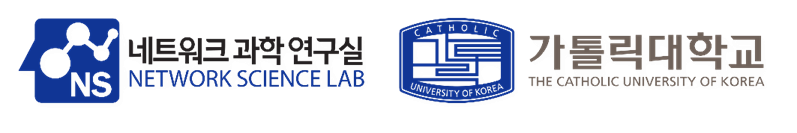

# Week 9: Explainability, Generalizability and Robustness

<a target="_blank" href="https://colab.research.google.com/github/NSLab-CUK/Graph-Neural-Networks-Fall-2026/blob/main/W9/SampleCode_9.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

### Can we trust a GNN?

Accuracy alone is not enough. This notebook looks at two questions:

* **Explainability**: *why* did the model make this prediction? We use **GNNExplainer** on molecules whose true explanation is known, and compare the two.
* **Robustness**: what happens when the graph, the features or the labels are **noisy**? We perturb Cora in three ways, then see how **ProGNN** repairs a noisy graph.

<!-- Helper cells (imports, plotting) are collapsed; click on them to see the code. -->

## Table of contents

- [1. Setup](#1-setup)
- **Part A: Explainability**
- [2. Mutagenicity: molecules with a known explanation](#2-mutagenicity-molecules-with-a-known-explanation)
- [3. Train a GIN classifier](#3-train-a-gin-classifier)
- [4. GNNExplainer: ground truth vs. explanation](#4-gnnexplainer-ground-truth-vs-explanation)
- **Part B: Robustness**
- [5. Three kinds of noise](#5-three-kinds-of-noise)
- [6. Does noise hurt a GCN?](#6-does-noise-hurt-a-gcn)
- [7. ProGNN: clean the graph while training](#7-prognn-clean-the-graph-while-training)
- [8. Takeaways](#8-takeaways)

## 1. Setup

In [1]:
# @title Install dependencies (Colab)
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric", "rdkit"])

In [2]:
# @title Imports and colors
import contextlib
import io
import tempfile
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # Optional PyG extension notices.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle
import networkx as nx
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
RDLogger.DisableLog("rdApp.*")                         # silence RDKit warnings

import torch
import torch.nn.functional as F
from torch_geometric.datasets import TUDataset, Planetoid
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_add_pool
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import to_dense_adj, to_networkx

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
ROOT = f"{tempfile.gettempdir()}/pyg_datasets"  # PyG downloads datasets here on first use.

# One color per role, reused in every figure.
GCN_COLOR, PROGNN_COLOR = "#2a78d6", "#1baf7a"
NOISE_COLOR, GT_COLOR, GLOW_COLOR = "#e34948", "#eda100", "#c03cff"
REAL_COLOR, SELF_COLOR = "#7a7a7a", "#4a3aa7"
CLASS_COLORS = ["#2a78d6", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#8c6d46"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.11.0+cu128 | device: cuda


# Part A: Explainability

## 2. Mutagenicity: molecules with a known explanation

To *evaluate* an explainer we need graphs where we already know the right answer. **Mutagenicity** (4,337 molecules) is the standard choice:

* **Nodes** = atoms (14 element types, one-hot), **edges** = chemical bonds.
* **Label** = *mutagen* (can damage DNA) or *non-mutagen*.
* Chemists know that two groups of atoms make a molecule mutagenic: the **nitro group NO₂** and the **amino group NH₂**. Their bonds are our **ground-truth explanation**.

In [3]:
with contextlib.redirect_stderr(io.StringIO()):   # hide PyG's download log
    mol_ds = TUDataset(ROOT, "Mutagenicity").shuffle()

ATOMS = ["C", "O", "Cl", "H", "N", "F", "Br", "S", "P", "I", "Na", "K", "Li", "Ca"]
MUTAGEN = 0                                        # class 0 = mutagen, 1 = non-mutagen

def ground_truth(mol):
    # Mark the bonds of every NO2 / NH2 group: an N atom with exactly two O (or two H) neighbors.
    atom = mol.x.argmax(1)
    src, dst = mol.edge_index
    in_group = torch.zeros(mol.num_nodes, dtype=torch.bool)
    for n in (atom == ATOMS.index("N")).nonzero().flatten():
        nbrs = dst[src == n]
        for el in ("O", "H"):
            partners = nbrs[atom[nbrs] == ATOMS.index(el)]
            if len(partners) == 2:
                in_group[n] = in_group[partners] = True
    return in_group[src] & in_group[dst]            # edge mask

split = int(0.8 * len(mol_ds))
train_mols, test_mols = mol_ds[:split], mol_ds[split:]
has_group = torch.tensor([ground_truth(m).any().item() for m in mol_ds])
print(f"{len(mol_ds)} molecules | {train_mols.num_node_features} atom types | train {len(train_mols)} / test {len(test_mols)}")
print(f"share with NO2/NH2:  mutagens {has_group[mol_ds.y == 0].float().mean():.0%}   "
      f"non-mutagens {has_group[mol_ds.y == 1].float().mean():.0%}")

4337 molecules | 14 atom types | train 3469 / test 868


share with NO2/NH2:  mutagens 43%   non-mutagens 18%


The groups are a strong (but not perfect) signal: mutagens are far more likely to contain them.

In [4]:
# @title Helper: draw a molecule
ATOM_COLORS = {"C": "#4d4d4d", "O": "#e34948", "N": "#2a78d6", "H": "#e6e6e6", "Cl": "#1baf7a"}
BOND_TYPES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE]
VALENCE = {"N": 3, "O": 2}                             # an N with 4 bonds (e.g. in NO2) is N+

def coords_3d(mol):
    # PyG graph -> RDKit molecule -> 3D coordinates (one row per atom).
    rd = Chem.RWMol()
    for a in mol.x.argmax(1).tolist():
        atom = Chem.Atom(ATOMS[a])
        atom.SetNoImplicit(True)                       # hydrogens are already explicit nodes
        rd.AddAtom(atom)
    for (s, t), b in zip(mol.edge_index.t().tolist(), mol.edge_attr.argmax(1).tolist()):
        if s < t:
            rd.AddBond(s, t, BOND_TYPES[b])
    for atom in rd.GetAtoms():
        extra = sum(b.GetBondTypeAsDouble() for b in atom.GetBonds()) - VALENCE.get(atom.GetSymbol(), 99)
        if extra > 0:
            atom.SetFormalCharge(int(extra))
    rd.UpdatePropertyCache(strict=False)
    if AllChem.EmbedMolecule(rd, randomSeed=SEED) != 0:              # rare failure: retry from random coords
        AllChem.EmbedMolecule(rd, randomSeed=SEED, useRandomCoords=True)
    return rd.GetConformer().GetPositions()

def rotate(xyz, azim, elev):
    xyz = xyz - xyz.mean(0)
    xyz = xyz @ np.linalg.svd(xyz, full_matrices=False)[2].T   # face-on: flattest direction points at the viewer
    a, e = np.radians(azim), np.radians(elev)
    Ry = np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(e), -np.sin(e)], [0, np.sin(e), np.cos(e)]])
    return xyz @ Ry.T @ Rx.T

def draw_molecule(ax, mol, gt=None, score=None, title="", azim=25, elev=15):
    # Ball-and-stick drawing. gt: amber halo on ground-truth bonds. score: purple glow, brighter = more important.
    x, y, z = rotate(coords_3d(mol), azim, elev).T     # z = depth (larger = closer to the viewer)
    scale = 1 + 0.08 * (z - z.mean())                  # simple perspective
    atom = [ATOMS[i] for i in mol.x.argmax(1).tolist()]
    eid = {(s, t): e for e, (s, t) in enumerate(mol.edge_index.t().tolist())}
    w = None if score is None else (score / score.max()).numpy()
    for (s, t), e in eid.items():
        if s > t:
            continue
        depth = (z[s] + z[t]) / 2
        if gt is not None and gt[e]:
            ax.plot(x[[s, t]], y[[s, t]], color=GT_COLOR, lw=13, alpha=0.55, solid_capstyle="round", zorder=depth - 0.01)
        if w is not None:                              # glow = several wide, faint strokes
            we = max(w[e], w[eid[(t, s)]]) ** 1.5
            for lw, alpha in [(44, 0.07), (32, 0.12), (22, 0.2), (13, 0.35), (7, 0.7)]:
                ax.plot(x[[s, t]], y[[s, t]], color=GLOW_COLOR, lw=lw * we, alpha=alpha * we, solid_capstyle="round", zorder=-100)
        ax.plot(x[[s, t]], y[[s, t]], color="#8a8a8a", lw=3, zorder=depth)
    for i, a in enumerate(atom):                       # atoms: a sphere with a small highlight
        r = (0.18 if a == "H" else 0.32) * scale[i]
        ax.add_patch(Circle((x[i], y[i]), r, color=ATOM_COLORS.get(a, "#8c6d46"), ec="black", lw=0.5, zorder=z[i] + 0.02))
        ax.add_patch(Circle((x[i] - 0.45 * r, y[i] + 0.45 * r), 0.22 * r, color="white", alpha=0.5, lw=0, zorder=z[i] + 0.03))
        if a not in ("C", "H"):
            ax.text(x[i], y[i], a, ha="center", va="center", fontsize=7, color="white", fontweight="bold", zorder=z[i] + 0.04)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.axis("off")
    ax.set_title(title, fontsize=11)

## 3. Train a GIN classifier

A 3-layer **GIN** (Graph Isomorphism Network) with sum pooling, a strong baseline for molecule classification.

In [5]:
class GIN(torch.nn.Module):
    def __init__(self, in_dim, hidden=64, num_classes=2):
        super().__init__()
        mlp = lambda d: torch.nn.Sequential(torch.nn.Linear(d, hidden), torch.nn.ReLU(),
                                            torch.nn.Linear(hidden, hidden))
        self.convs = torch.nn.ModuleList([GINConv(mlp(in_dim)), GINConv(mlp(hidden)), GINConv(mlp(hidden))])
        self.lin = torch.nn.Linear(hidden, num_classes)

    def forward(self, x, edge_index, batch=None):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
        return self.lin(global_add_pool(x, batch))    # one score vector per molecule

@torch.no_grad()
def test_accuracy(model, mols):
    model.eval()
    correct = 0
    for b in DataLoader(mols, batch_size=256):
        b = b.to(DEVICE)
        correct += (model(b.x, b.edge_index, b.batch).argmax(1) == b.y).sum().item()
    return correct / len(mols)

gin = GIN(mol_ds.num_node_features).to(DEVICE)
optimizer = torch.optim.Adam(gin.parameters(), lr=0.005)
for epoch in range(1, 61):
    gin.train()
    for b in DataLoader(train_mols, batch_size=64, shuffle=True):
        b = b.to(DEVICE)
        optimizer.zero_grad()
        F.cross_entropy(gin(b.x, b.edge_index, b.batch), b.y).backward()
        optimizer.step()
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d} | test accuracy {test_accuracy(gin, test_mols):.3f}")

epoch  20 | test accuracy 0.760


epoch  40 | test accuracy 0.815


epoch  60 | test accuracy 0.808


## 4. GNNExplainer: ground truth vs. explanation

**GNNExplainer** (Ying et al., 2019) learns a soft **mask** $M \in [0,1]^{|E|}$ over the edges. It keeps the edges that matter for the prediction and drops the rest:

$$\max_{M}\; \underbrace{\log P_\Phi\big(Y = \hat y \mid G \odot M\big)}_{\text{keep the prediction}} \;-\; \underbrace{\lambda_1 \lVert M\rVert_1}_{\text{small explanation}} \;-\; \underbrace{\lambda_2\, H(M)}_{\text{near } 0/1 \text{ mask}}$$

The trained GIN is **frozen**; only the mask is optimized. We raise the size penalty $\lambda_1$ (`edge_size`) from PyG's default 0.005 to 0.05, which gives a more compact explanation.

In [6]:
explainer = Explainer(
    model=gin,
    algorithm=GNNExplainer(epochs=200, edge_size=0.05),   # edge_size = lambda_1
    explanation_type="model",             # explain the model's own prediction
    edge_mask_type="object",              # one importance score per edge
    node_mask_type=None,
    model_config=dict(mode="multiclass_classification", task_level="graph", return_type="raw"),
)

def explain(mol):
    batch = torch.zeros(mol.num_nodes, dtype=torch.long, device=DEVICE)
    return explainer(mol.x.to(DEVICE), mol.edge_index.to(DEVICE), batch=batch).edge_mask.cpu()

@torch.no_grad()
def predict(mol):
    gin.eval()
    return gin(mol.x.to(DEVICE), mol.edge_index.to(DEVICE)).argmax().item()

# Explain correctly predicted test mutagens that contain a ground-truth group (18-26 atoms, easy to read).
examples = [m for m in test_mols if m.y.item() == MUTAGEN and ground_truth(m).any()
            and predict(m) == MUTAGEN and 18 <= m.num_nodes <= 26][:3]
masks = [explain(m) for m in examples]

Left: what chemists say (amber). Right: what GNNExplainer found (the brighter the purple glow, the more important the bond).

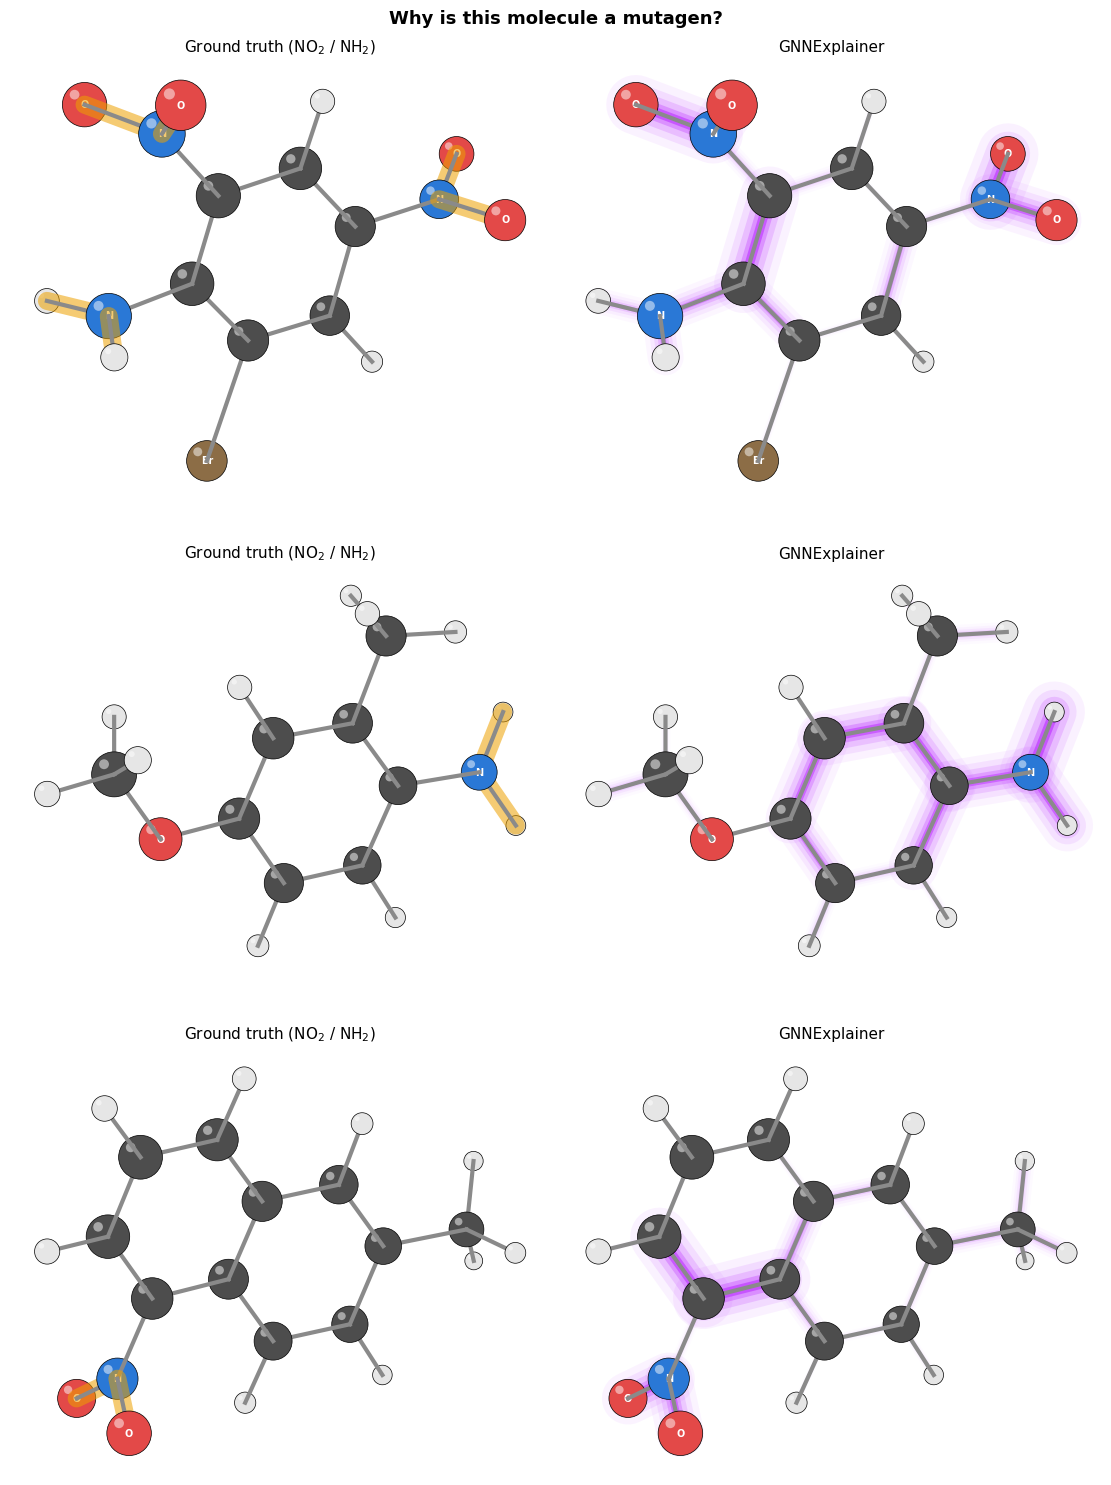

In [7]:
# @title Plot: ground truth vs. GNNExplainer
fig, axes = plt.subplots(3, 2, figsize=(11, 15), constrained_layout=True)
for row, mol, mask in zip(axes, examples, masks):
    draw_molecule(row[0], mol, gt=ground_truth(mol), title="Ground truth (NO$_2$ / NH$_2$)")
    draw_molecule(row[1], mol, score=mask, title="GNNExplainer")
fig.suptitle("Why is this molecule a mutagen?", fontsize=13, fontweight="bold")
plt.show()

The brightest bonds tend to sit **on or next to the NO₂ / NH₂ groups**: the GIN has learned to look where chemists look. The match is not perfect:

* Importance spreads to nearby ring bonds, because message passing mixes each atom with its neighbors.
* An explainer shows what the **model** uses. If the GIN also relies on other patterns (e.g. ring systems), so does its explanation.
* GNNExplainer solves a non-convex problem for each molecule, so its masks are somewhat noisy (and change a little between runs).

# Part B: Robustness

## 5. Three kinds of noise

Real graphs are messy. We use **Cora** (2,708 papers, 7 topics) and corrupt one ingredient at a time:

| Noise | What we change | In practice |
|:--|:--|:--|
| **Structure** | add fake edges between papers of *different* topics | spam links, fake accounts |
| **Features** | randomly flip words in the bag-of-words (0 ↔ 1) | typos, noisy sensors |
| **Labels** | flip some *training* labels to a wrong topic | annotation mistakes |

In [8]:
with contextlib.redirect_stderr(io.StringIO()):
    cora = Planetoid(ROOT, "Cora")[0]
A = to_dense_adj(cora.edge_index, max_num_nodes=cora.num_nodes)[0]   # dense 0/1 adjacency
NUM_CLASSES = int(cora.y.max()) + 1

def add_fake_edges(A, y, rate, seed=0):
    # Add rate * |E| edges, each joining two nodes of different classes.
    g = torch.Generator().manual_seed(seed)
    n, n_add = A.size(0), int(rate * A.triu(1).sum())
    src, dst = torch.randint(0, n, (2, 10 * n_add + 10), generator=g)
    ok = (y[src] != y[dst]) & (A[src, dst] == 0)
    src, dst = src[ok][:n_add], dst[ok][:n_add]
    A = A.clone()
    A[src, dst] = A[dst, src] = 1
    return A

def flip_features(X, p, seed=0):
    # Flip every 0/1 entry independently with probability p.
    g = torch.Generator().manual_seed(seed)
    return torch.where(torch.rand(X.shape, generator=g) < p, 1 - X, X)

def flip_labels(y, rate, seed=0):
    # Move a fraction `rate` of the nodes to a random *other* class.
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(y), generator=g)[: int(rate * len(y))]
    y = y.clone()
    y[idx] = (y[idx] + torch.randint(1, NUM_CLASSES, (len(idx),), generator=g)) % NUM_CLASSES
    return y

### 5.1. What does the noise look like?

Each kind of noise applied to a small piece of Cora (60 papers), drawn with a fixed layout:

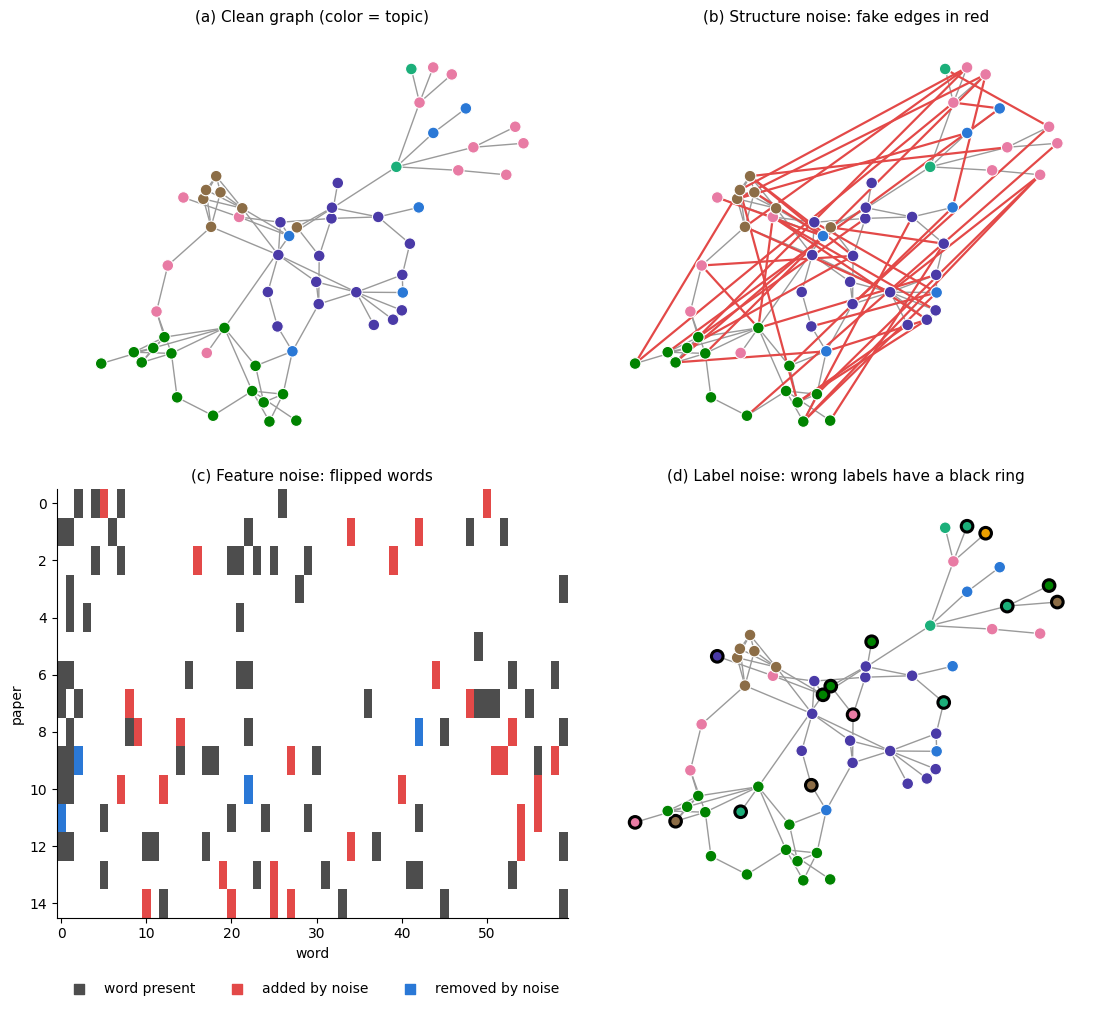

In [9]:
# @title Plot: the three kinds of noise
sub = list(nx.bfs_tree(to_networkx(cora, to_undirected=True), 2229))[:60]
A_sub, X_sub, y_sub = A[sub][:, sub], cora.x[sub], cora.y[sub]
pos = nx.spring_layout(nx.from_numpy_array(A_sub.numpy()), seed=SEED)

def draw_graph(ax, A_draw, labels, title, fake=None, ring=None):
    G = nx.from_numpy_array(A_draw.numpy())
    is_fake = lambda u, v: fake is not None and bool(fake[u, v])
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=[e for e in G.edges() if not is_fake(*e)], edge_color="#9a9a9a", width=1)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=[e for e in G.edges() if is_fake(*e)], edge_color=NOISE_COLOR, width=1.6)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=70, node_color=[CLASS_COLORS[int(c)] for c in labels],
                           edgecolors=["black" if ring is not None and ring[i] else "white" for i in G.nodes()],
                           linewidths=[2.2 if ring is not None and ring[i] else 0.8 for i in G.nodes()])
    ax.set_title(title, fontsize=11)
    ax.axis("off")

A_noisy = add_fake_edges(A_sub, y_sub, rate=0.5)
X_noisy = flip_features(X_sub, p=0.03)
y_noisy = flip_labels(y_sub, rate=0.25)

fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
draw_graph(axes[0, 0], A_sub, y_sub, "(a) Clean graph (color = topic)")
draw_graph(axes[0, 1], A_noisy, y_sub, "(b) Structure noise: fake edges in red", fake=A_noisy - A_sub)
draw_graph(axes[1, 1], A_sub, y_noisy, "(d) Label noise: wrong labels have a black ring", ring=y_noisy != y_sub)

# (c) Features of 15 papers x 60 common words: 0 = absent, 1 = present, 2 = added by noise, 3 = removed by noise
words = cora.x.sum(0).argsort(descending=True)[:60]
before, after = X_sub[:15][:, words], X_noisy[:15][:, words]
cmap = ListedColormap(["white", "#4d4d4d", NOISE_COLOR, GCN_COLOR])
axes[1, 0].imshow(before + 2 * (after != before), cmap=cmap, vmin=-0.5, vmax=3.5, aspect="auto")
axes[1, 0].set_title("(c) Feature noise: flipped words", fontsize=11)
axes[1, 0].set(xlabel="word", ylabel="paper")
axes[1, 0].grid(False)
for c, name in [(1, "word present"), (2, "added by noise"), (3, "removed by noise")]:
    axes[1, 0].scatter([], [], marker="s", s=60, color=cmap(c), label=name)
axes[1, 0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.show()

## 6. Does noise hurt a GCN?

We train the same 2-layer GCN on the clean data and on each noisy version. The GCN uses a **dense** adjacency matrix $\hat A = D^{-1/2}(A + I)D^{-1/2}$, because ProGNN (next section) learns a dense matrix.

In [10]:
# @title Helper: dense GCN and its training loop
X = F.normalize(cora.x, dim=1).to(DEVICE)              # row-normalized features
A, Y = A.to(DEVICE), cora.y.to(DEVICE)
TRAIN, VAL, TEST = cora.train_mask.to(DEVICE), cora.val_mask.to(DEVICE), cora.test_mask.to(DEVICE)

def normalize(A):
    A = A + torch.eye(A.size(0), device=A.device)
    d = A.sum(1).pow(-0.5)
    return d[:, None] * A * d[None, :]

class DenseGCN(torch.nn.Module):
    def __init__(self, in_dim, hidden=16, num_classes=NUM_CLASSES):
        super().__init__()
        self.lin1, self.lin2 = torch.nn.Linear(in_dim, hidden), torch.nn.Linear(hidden, num_classes)

    def forward(self, x, A_hat):
        x = F.dropout(x, 0.5, self.training)
        x = F.relu(A_hat @ self.lin1(x))
        x = F.dropout(x, 0.5, self.training)
        return A_hat @ self.lin2(x)

@torch.no_grad()
def evaluate(model, x, A_hat):
    model.eval()
    pred = model(x, A_hat).argmax(1)
    return [(pred[m] == Y[m]).float().mean().item() for m in (VAL, TEST)]

def train_gcn(x, A, y_train, epochs=200):
    torch.manual_seed(SEED)
    model = DenseGCN(x.size(1)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    A_hat, best = normalize(A), (0, 0)
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        F.cross_entropy(model(x, A_hat)[TRAIN], y_train[TRAIN]).backward()
        opt.step()
        best = max(best, tuple(evaluate(model, x, A_hat)))   # (val, test) at the best validation accuracy
    return best[1]

In [11]:
A_fake = add_fake_edges(A.cpu(), Y.cpu(), rate=1.0).to(DEVICE)             # as many fake edges as real ones
X_flip = F.normalize(flip_features(cora.x, p=0.03), dim=1).to(DEVICE)      # 3% of words flipped
Y_flip = torch.where(TRAIN, flip_labels(Y.cpu(), rate=0.3).to(DEVICE), Y)  # 30% of training labels wrong

gcn_acc = {
    "Clean":     train_gcn(X, A, Y),
    "Structure": train_gcn(X, A_fake, Y),
    "Features":  train_gcn(X_flip, A, Y),
    "Labels":    train_gcn(X, A, Y_flip),
}

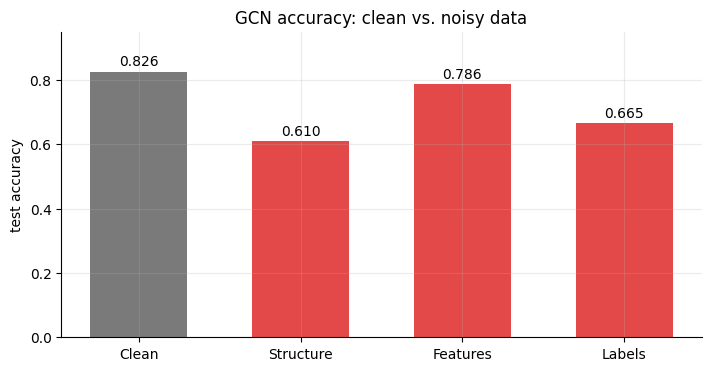

In [12]:
# @title Plot: GCN accuracy under noise
fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
bars = ax.bar(gcn_acc.keys(), gcn_acc.values(), color=[REAL_COLOR] + [NOISE_COLOR] * 3, width=0.6)
ax.bar_label(bars, fmt="%.3f", padding=2)
ax.set(ylabel="test accuracy", ylim=(0, 0.95), title="GCN accuracy: clean vs. noisy data")
plt.show()

* **Structure** noise hurts the most: a GCN *averages* each node with its neighbors, so fake edges mix in papers on other topics.
* **Label** noise hurts too: the GCN learns from wrong answers.
* **Feature** noise hurts only a little: random flips differ from paper to paper, so averaging over neighbors cancels much of it.

## 7. ProGNN: clean the graph while training

**Idea**: don't trust the given graph $A$. Instead, **learn a cleaned graph $S$** at the same time as the GCN. ProGNN (Jin et al., KDD 2020) uses what we know about real, clean graphs:

| Property of a clean graph | Term in the loss | Effect on fake edges |
|:--|:--|:--|
| close to the observed graph | $\lVert A - S\rVert_F^2$ | keeps the real edges |
| **sparse** (few edges) | $\alpha \lVert S\rVert_1$ | removes weak edges |
| **low rank** (a few communities) | $\beta \lVert S\rVert_*$ | random edges raise the rank, so they are removed |
| **smooth features** (similar papers link) | $\lambda \operatorname{tr}(X^\top L_S X)$ | edges between dissimilar papers cost more |

Each epoch alternates two steps: **(1)** update $S$ with these terms plus the GCN loss, **(2)** train the GCN for one step on $S$.

> Simplifications for a short demo: the plain Laplacian $L_S = D_S - S$ instead of the normalized one, and one $S$-step per GCN step.

In [13]:
def feature_smoothness(S, X):
    L = torch.diag(S.sum(1)) - S                       # Laplacian of the learned graph
    return torch.trace(X.t() @ L @ X)                  # = 1/2 * sum_ij S_ij * ||x_i - x_j||^2

def prognn(x, A, y_train, epochs=200, alpha=5e-4, beta=1.5, lam=1.5, lr_adj=0.01):
    torch.manual_seed(SEED)
    model = DenseGCN(x.size(1)).to(DEVICE)
    opt_gcn = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    S = A.clone().requires_grad_(True)                 # learned graph, starts as the noisy one
    opt_S = torch.optim.SGD([S], lr=lr_adj, momentum=0.9)
    best = (0, 0)

    for _ in range(epochs):
        # (1) Update the graph S, with the GCN fixed
        model.train()
        opt_S.zero_grad()
        loss_S = (torch.norm(S - A) ** 2                                             # stay close to A
                  + F.cross_entropy(model(x, normalize(S))[TRAIN], y_train[TRAIN])   # help the GCN
                  + lam * feature_smoothness(S, x))                                  # connect similar nodes
        loss_S.backward()
        opt_S.step()
        with torch.no_grad():
            S.copy_((S + S.t()) / 2)
            eigval, U = torch.linalg.eigh(S)                                         # low rank: shrink eigenvalues
            S.copy_(U @ torch.diag(eigval.sign() * F.relu(eigval.abs() - lr_adj * beta)) @ U.t())
            S.copy_(F.relu(S - lr_adj * alpha))                                      # sparse: shrink every entry
            S.clamp_(0, 1)                                                           # valid edge weights

        # (2) Update the GCN on the current graph, with S fixed
        A_hat = normalize(S.detach())
        opt_gcn.zero_grad()
        F.cross_entropy(model(x, A_hat)[TRAIN], y_train[TRAIN]).backward()
        opt_gcn.step()
        best = max(best, tuple(evaluate(model, x, A_hat)))
    return best[1], S.detach()

We train ProGNN on the graph with **fake edges** (as many fake edges as real ones) and compare it with the GCN from Section 6:

In [14]:
acc_prognn, S = prognn(X, A_fake, Y)
print(f"GCN on clean graph : {gcn_acc['Clean']:.3f}")
print(f"GCN on noisy graph : {gcn_acc['Structure']:.3f}")
print(f"ProGNN, noisy graph: {acc_prognn:.3f}")

GCN on clean graph : 0.826
GCN on noisy graph : 0.610
ProGNN, noisy graph: 0.647



## 8. Takeaways

* **Explainability**: GNNExplainer learns a small edge mask that keeps the prediction. On Mutagenicity it largely finds the chemically known **NO₂ / NH₂** groups. An explainer shows what the **model** uses, which is not always the true cause.
* **Robustness**: noise can hit the **structure**, the **features** or the **labels**. A GCN suffers most from fake edges, because it averages over neighbors.
* **ProGNN** treats the graph as something to learn: a sparse, low-rank, feature-smooth $S$ close to $A$. It **down-weights fake edges** and leans more on each node's own features, which makes the GCN more robust to structure noise.

### Further reading
- Ying et al. *GNNExplainer: Generating Explanations for Graph Neural Networks.* NeurIPS 2019.
- Kazius, McGuire & Bursi. *Derivation and Validation of Toxicophores for Mutagenicity Prediction.* J. Med. Chem., 2005 (the Mutagenicity dataset).
- Agarwal et al. *Evaluating Explainability for Graph Neural Networks.* Scientific Data, 2023 (benchmarks with ground-truth explanations).
- Jin et al. *Graph Structure Learning for Robust Graph Neural Networks (Pro-GNN).* KDD 2020.